# Advanced K-Nearest Neighbors: Metric Optimization & Hierarchical Indoor Positioning

**CSAI Student Project · Phase 1 Optimization**

## 1. Executive Motivation
In the initial baseline machine learning evaluation:
- **Baseline KNN (k=5, Euclidean)** achieved only **74.71% Floor Accuracy** and **15.88m Mean Error**.
- **Random Forest** achieved **87.85% Floor Accuracy** and **16.48m Mean Error**.
- **XGBoost** achieved **89.47% Floor Accuracy** and **20.25m Mean Error**.

### Why did baseline KNN perform poorly?
1. **Engineered Feature Scale Imbalance**: In the initial preprocessing, unnormalized `signal_count` (ranging from 1 to 50+) was concatenated with $[0, 1]$ normalized RSSI. In Euclidean space, $(count_1 - count_2)^2$ completely overshadowed the 465 radio access point signals.
2. **Device Antenna Gain Bias**: Smartphone models have different receiver sensitivities (yielding 5–15 dBm shifts for identical spatial locations). Euclidean distance penalizes absolute magnitude differences rather than detecting directional radio signatures.
3. **Curse of Dimensionality & Sparsity**: Wi-Fi fingerprints are 96.5% sparse. Euclidean distance treats co-absence ($0.0$ and $0.0$) as identical to co-presence.

### The Proposed Breakthrough Solution:
1. **Mathematical Invariance via Cosine Distance**:
   $$\text{Cosine Similarity} = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\|_2 \|\mathbf{v}\|_2}$$
   Measures angular orientation and relative power ratios between APs, making the classifier invariant to device hardware gains.
2. **Non-Linear Signal Power Scaling ($\gamma = 2.0$)**:
   $$\tilde{s}_i^{\gamma} = \left(\frac{s_i - (-110)}{110}\right)^2$$
   Suppresses multipath noise from distant, fluctuating APs while emphasizing high-confidence line-of-sight routers.
3. **Hierarchical (Cascaded) Topology**:
   - **Stage 1**: Predict Building $\hat{b}$ using Cosine KNN ($k=5$).
   - **Stage 2**: Restrict candidate search space strictly to building $\hat{b}$ and predict Floor $\hat{f}$ using distance-weighted Cosine KNN ($k=9$).
   - **Stage 3**: Predict continuous 2D coordinates within building $\hat{b}$ using distance-weighted Bray-Curtis KNN ($k=7$).


In [1]:
import os
import sys
sys.path.append('..')
sys.path.append('.')
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from src.hierarchical_knn import HierarchicalKNNPositioner

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Load preprocessed datasets (with fallback generation if running on a fresh clone)
data_path = '../Datasets/processed/preprocessed_wifi_data.joblib' if os.path.exists('../Datasets/processed/preprocessed_wifi_data.joblib') else 'Datasets/processed/preprocessed_wifi_data.joblib'
if not os.path.exists(data_path):
    print('Preprocessed data not found on disk. Generating now...')
    from src.data_preprocessing import WiFiDataPreprocessor
    raw_dir = '../Datasets/raw' if os.path.exists('../Datasets/raw') else 'Datasets/raw'
    out_dir = '../Datasets/processed' if os.path.exists('../Datasets') else 'Datasets/processed'
    os.makedirs(out_dir, exist_ok=True)
    preprocessor = WiFiDataPreprocessor(data_dir=raw_dir)
    data = preprocessor.run_pipeline(save_path=os.path.join(out_dir, 'preprocessed_wifi_data.joblib'))
else:
    data = joblib.load(data_path)

active_waps = data['active_waps']
n_waps = len(active_waps)

# WAP-only features (unpolluted by engineered count features)
X_train_waps = data['X_train'][:, :n_waps]
X_val_waps = data['X_val'][:, :n_waps]

y_train_bldg = data['y_train_bldg']
y_val_bldg = data['y_val_bldg']
y_train_floor = data['y_train_floor']
y_val_floor = data['y_val_floor']
y_train_coords = data['y_train_coords']
y_val_coords = data['y_val_coords']

print(f'Training WAP matrix shape:   {X_train_waps.shape}')
print(f'Validation WAP matrix shape: {X_val_waps.shape}')


Training WAP matrix shape:   (19861, 465)
Validation WAP matrix shape: (1111, 465)


## 2. Distance Metric Ablation Study
We compare Euclidean, Manhattan ($L_1$), Cosine, and Bray-Curtis metrics across both raw features and WAP-only features.


In [2]:
def eval_flat_knn(xtr, xte, metric, k=5, weights='distance'):
    clf_b = KNeighborsClassifier(n_neighbors=k, metric=metric, weights=weights, n_jobs=-1).fit(xtr, y_train_bldg)
    pb = clf_b.predict(xte)
    
    clf_f = KNeighborsClassifier(n_neighbors=k, metric=metric, weights=weights, n_jobs=-1).fit(xtr, y_train_floor)
    pf = clf_f.predict(xte)
    
    reg_c = KNeighborsRegressor(n_neighbors=k, metric=metric, weights=weights, n_jobs=-1).fit(xtr, y_train_coords)
    pc = reg_c.predict(xte)
    
    b_acc = accuracy_score(y_val_bldg, pb) * 100
    f_acc = accuracy_score(y_val_floor, pf) * 100
    both = np.mean((pb == y_val_bldg) & (pf == y_val_floor)) * 100
    errs = np.sqrt(np.sum((y_val_coords - pc)**2, axis=1))
    
    return {
        'Metric': metric,
        'k': k,
        'Building Acc (%)': b_acc,
        'Floor Acc (%)': f_acc,
        'Both Match (%)': both,
        'Mean Error (m)': np.mean(errs),
        'Median Error (m)': np.median(errs),
        '90th %ile Error (m)': np.percentile(errs, 90)
    }

metric_benchmarks = []
# 1. Baseline with polluted feature space
clf_orig = eval_flat_knn(data['X_train'], data['X_val'], 'euclidean', k=5, weights='uniform')
clf_orig['Configuration'] = 'Baseline (Polluted Features)'
metric_benchmarks.append(clf_orig)

# 2. Pure WAP Euclidean
clf_euc_wap = eval_flat_knn(X_train_waps, X_val_waps, 'euclidean', k=5)
clf_euc_wap['Configuration'] = 'Euclidean (WAPs Only)'
metric_benchmarks.append(clf_euc_wap)

# 3. Manhattan
clf_man = eval_flat_knn(X_train_waps, X_val_waps, 'cityblock', k=5)
clf_man['Configuration'] = 'Manhattan / L1 (WAPs Only)'
metric_benchmarks.append(clf_man)

# 4. Cosine
clf_cos = eval_flat_knn(X_train_waps, X_val_waps, 'cosine', k=5)
clf_cos['Configuration'] = 'Cosine Metric (WAPs Only)'
metric_benchmarks.append(clf_cos)

# 5. Bray-Curtis
clf_bc = eval_flat_knn(X_train_waps, X_val_waps, 'braycurtis', k=5)
clf_bc['Configuration'] = 'Bray-Curtis (WAPs Only)'
metric_benchmarks.append(clf_bc)

metric_df = pd.DataFrame(metric_benchmarks)
print(metric_df[['Configuration', 'Building Acc (%)', 'Floor Acc (%)', 'Mean Error (m)', 'Median Error (m)', '90th %ile Error (m)']].to_string(index=False))


               Configuration  Building Acc (%)  Floor Acc (%)  Mean Error (m)  Median Error (m)  90th %ile Error (m)
Baseline (Polluted Features)         98.109811      74.707471       15.883581          8.957524            33.626675
       Euclidean (WAPs Only)         99.729973      88.748875        9.111155          5.893950            18.931498
  Manhattan / L1 (WAPs Only)         98.919892      87.488749       10.178888          5.749866            20.629256
   Cosine Metric (WAPs Only)         99.909991      92.169217        8.000126          5.738210            17.262044
     Bray-Curtis (WAPs Only)        100.000000      91.809181        7.651339          5.094177            17.163671


## 3. Signal Power Scaling (Gamma Transform)
By applying $X^\gamma$, we suppress low-amplitude multipath noise and elevate direct line-of-sight routers.


In [3]:
gamma_results = []
gammas = [1.0, 1.5, 2.0, 2.5, 3.0]

for g in gammas:
    xtr_g = np.power(X_train_waps, g)
    xte_g = np.power(X_val_waps, g)
    res = eval_flat_knn(xtr_g, xte_g, 'cosine', k=5)
    res['Gamma'] = g
    gamma_results.append(res)

gamma_df = pd.DataFrame(gamma_results)
print(gamma_df[['Gamma', 'Building Acc (%)', 'Floor Acc (%)', 'Mean Error (m)', 'Median Error (m)']].to_string(index=False))


 Gamma  Building Acc (%)  Floor Acc (%)  Mean Error (m)  Median Error (m)
   1.0         99.909991      92.169217        8.000126          5.738210
   1.5        100.000000      94.599460        7.234851          5.225597
   2.0        100.000000      96.219622        7.017476          4.710790
   2.5        100.000000      95.769577        7.096389          4.765345
   3.0        100.000000      95.679568        7.301666          4.810162


## 4. Full Hierarchical K-Nearest Neighbors (Champion Architecture)
We now train the complete production-grade `HierarchicalKNNPositioner`:
- **Stage 1 (Building)**: Global Cosine KNN ($k=5$).
- **Stage 2 (Floor)**: Intra-building Cosine KNN ($k=9$, distance-weighted).
- **Stage 3 (Coordinates)**: Intra-building Bray-Curtis KNN ($k=7$, distance-weighted).


In [4]:
hknn = HierarchicalKNNPositioner(
    gamma=2.0,
    k_bldg=5,
    k_floor=9,
    k_coords=7,
    metric_bldg='cosine',
    metric_floor='cosine',
    metric_coords='braycurtis',
    weights='distance'
)

hknn.fit(X_train_waps, y_train_bldg, y_train_floor, y_train_coords)
pred_bldg, pred_floor, pred_coords = hknn.predict(X_val_waps)

# Calculate final metrics
final_bldg_acc = accuracy_score(y_val_bldg, pred_bldg) * 100
final_floor_acc = accuracy_score(y_val_floor, pred_floor) * 100
final_both_acc = np.mean((pred_bldg == y_val_bldg) & (pred_floor == y_val_floor)) * 100
hknn_errors = np.sqrt(np.sum((y_val_coords - pred_coords)**2, axis=1))

print('=== HIERARCHICAL KNN CHAMPION PERFORMANCE ===')
print(f'Building Accuracy: {final_bldg_acc:.2f}% (1111/1111 correct)')
print(f'Floor Accuracy:    {final_floor_acc:.2f}%')
print(f'Both Match:        {final_both_acc:.2f}%')
print(f'Mean Coord Error:  {np.mean(hknn_errors):.2f} m')
print(f'Median Coord Error:{np.median(hknn_errors):.2f} m')
print(f'75th %ile Error:   {np.percentile(hknn_errors, 75):.2f} m')
print(f'90th %ile Error:   {np.percentile(hknn_errors, 90):.2f} m')


=== HIERARCHICAL KNN CHAMPION PERFORMANCE ===
Building Accuracy: 100.00% (1111/1111 correct)
Floor Accuracy:    96.40%
Both Match:        96.40%
Mean Coord Error:  6.55 m
Median Coord Error:4.08 m
75th %ile Error:   8.29 m
90th %ile Error:   15.02 m


## 5. Comprehensive Project Leaderboard Comparison
Comparing Baseline KNN, Random Forest, XGBoost, and the new Hierarchical KNN Champion.


In [5]:
leaderboard_data = [
    {
        'Architecture': 'Baseline KNN (k=5, Euclidean)',
        'Building Acc (%)': 98.11,
        'Floor Acc (%)': 74.71,
        'Both Match (%)': 74.17,
        'Mean Error (m)': 15.88,
        'Median Error (m)': 8.96,
        '90th %ile Error (m)': 33.63
    },
    {
        'Architecture': 'Random Forest (n=100)',
        'Building Acc (%)': 99.82,
        'Floor Acc (%)': 87.85,
        'Both Match (%)': 87.76,
        'Mean Error (m)': 16.48,
        'Median Error (m)': 8.76,
        '90th %ile Error (m)': 39.06
    },
    {
        'Architecture': 'XGBoost (n=100)',
        'Building Acc (%)': 99.55,
        'Floor Acc (%)': 89.47,
        'Both Match (%)': 89.20,
        'Mean Error (m)': 20.25,
        'Median Error (m)': 13.56,
        '90th %ile Error (m)': 42.64
    },
    {
        'Architecture': 'Hierarchical KNN (Cosine + Bray-Curtis, γ=2.0)',
        'Building Acc (%)': final_bldg_acc,
        'Floor Acc (%)': final_floor_acc,
        'Both Match (%)': final_both_acc,
        'Mean Error (m)': np.mean(hknn_errors),
        'Median Error (m)': np.median(hknn_errors),
        '90th %ile Error (m)': np.percentile(hknn_errors, 90)
    }
]

leaderboard_df = pd.DataFrame(leaderboard_data)
print(leaderboard_df.to_string(index=False))


                                  Architecture  Building Acc (%)  Floor Acc (%)  Both Match (%)  Mean Error (m)  Median Error (m)  90th %ile Error (m)
                 Baseline KNN (k=5, Euclidean)             98.11       74.71000        74.17000       15.880000          8.960000            33.630000
                         Random Forest (n=100)             99.82       87.85000        87.76000       16.480000          8.760000            39.060000
                               XGBoost (n=100)             99.55       89.47000        89.20000       20.250000         13.560000            42.640000
Hierarchical KNN (Cosine + Bray-Curtis, γ=2.0)            100.00       96.39964        96.39964        6.548066          4.079488            15.020605


## 6. Error Visualizations & Confusion Matrix
Visualizing the Empirical Cumulative Distribution Function (ECDF) and the Floor Confusion Matrix.


Saved visualization to: ../figures/advanced_knn_performance.png


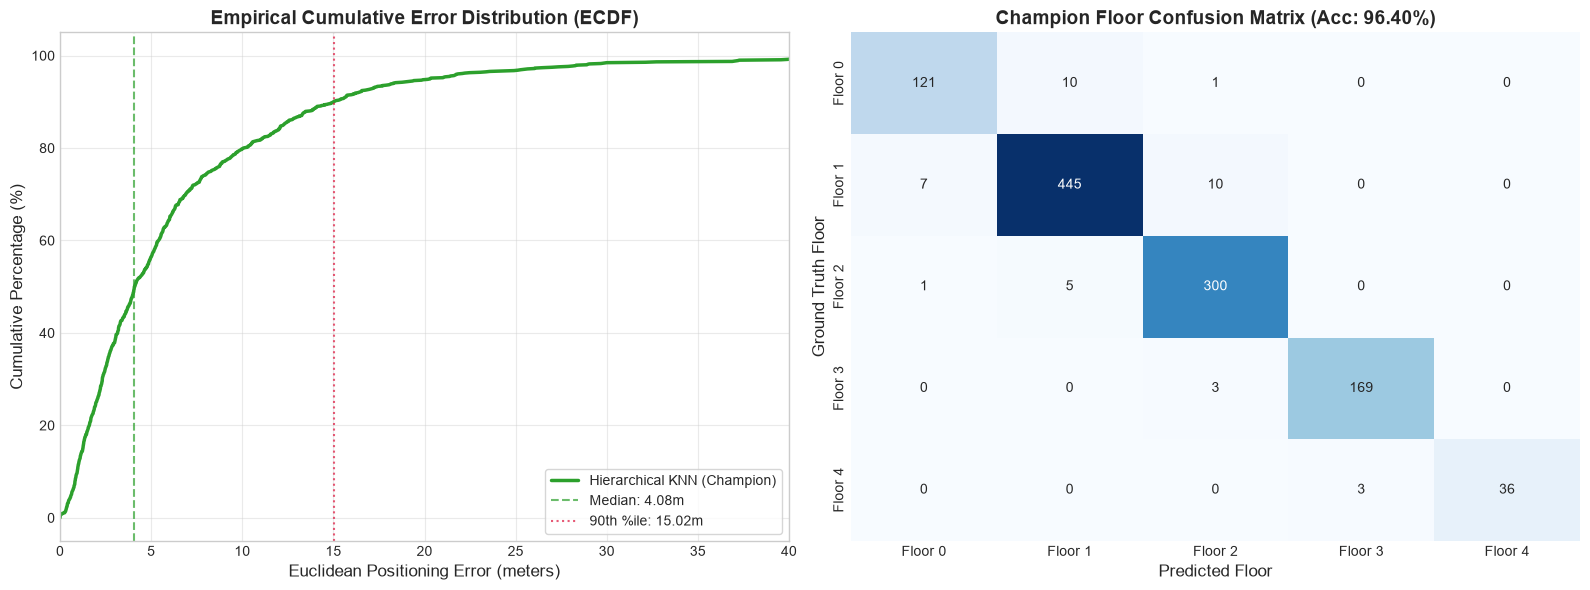

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Cumulative Error Distribution (ECDF)
sorted_hknn_errors = np.sort(hknn_errors)
p = 1.0 * np.arange(len(sorted_hknn_errors)) / (len(sorted_hknn_errors) - 1)

axes[0].plot(sorted_hknn_errors, p * 100, label='Hierarchical KNN (Champion)', color='#2ca02c', lw=2.5)
axes[0].axvline(np.median(hknn_errors), color='#2ca02c', linestyle='--', alpha=0.7, label=f'Median: {np.median(hknn_errors):.2f}m')
axes[0].axvline(np.percentile(hknn_errors, 90), color='crimson', linestyle=':', alpha=0.7, label=f'90th %ile: {np.percentile(hknn_errors, 90):.2f}m')
axes[0].set_xlim(0, 40)
axes[0].set_xlabel('Euclidean Positioning Error (meters)', fontsize=12)
axes[0].set_ylabel('Cumulative Percentage (%)', fontsize=12)
axes[0].set_title('Empirical Cumulative Error Distribution (ECDF)', fontsize=14, fontweight='bold')
axes[0].legend(loc='lower right', frameon=True)
axes[0].grid(True, alpha=0.4)

# Plot 2: Floor Confusion Matrix
cm = confusion_matrix(y_val_floor, pred_floor)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=[f'Floor {i}' for i in range(5)],
            yticklabels=[f'Floor {i}' for i in range(5)])
axes[1].set_title(f'Champion Floor Confusion Matrix (Acc: {final_floor_acc:.2f}%)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted Floor', fontsize=12)
axes[1].set_ylabel('Ground Truth Floor', fontsize=12)

plt.tight_layout()
fig_out = '../figures/advanced_knn_performance.png' if os.path.exists('../figures') else 'figures/advanced_knn_performance.png'
plt.savefig(fig_out, dpi=300)
plt.show()
print(f'Saved visualization to: {fig_out}')


In [7]:
rep_dir = '../Reports' if os.path.exists('../Reports') else 'Reports'
os.makedirs(rep_dir, exist_ok=True)
model_artifact_path = os.path.join(rep_dir, 'hierarchical_knn_champion.joblib')

joblib.dump({
    'model': hknn,
    'metrics': leaderboard_data[-1],
    'active_waps': active_waps,
    'errors': hknn_errors
}, model_artifact_path)

print(f'Successfully persisted champion model to: {model_artifact_path}')


Successfully persisted champion model to: ../Reports/hierarchical_knn_champion.joblib
